Fit a unimodal model to time series data using PCA to reduce dimension in the time series.

In-sample prediction is good as expected. Out of sample prediction shows varying degrees of bias, and increased variance as expected

In [1]:
import statistics
import scipy.stats as stats
import logging
from pyts.datasets import load_gunpoint
import matplotlib.pyplot as plt
import math
from typing import Optional
import itertools
import random
import copy

import seaborn as sns
import pandas as pd

import torch
import pyro
from pyro.infer import Predictive

from mmbo.mode.timeseries import TSPCA
from mmbo.mode.vae import VAE
from mmbo.examples.testfunc import timeseries_stat, timeseries_full
from mmbo.nn import RegBNN, RegBNNGuide, LayeredRegBNN, LayeredRegBNNGuide

In [2]:
logging.basicConfig(format='%(message)s', level=logging.INFO)

param_store = pyro.get_param_store()

In [3]:
def do_svi(svi, *args, check_interval=1000, max_nonimproved = 3, params = None, **kwargs):
    losses = []
    current_loss = 0
    nonimproved = 0
    best_loss = torch.inf
    if params is None:
        with pyro.get_param_store().scope() as params:
            pass
    best_params = copy.deepcopy(params)
    while nonimproved < max_nonimproved:
        with pyro.get_param_store().scope(params):
            loss = svi.step(*args, **kwargs)
        losses.append(loss)
        if len(losses) >= check_interval and len(losses) % check_interval == 0:
            current_loss = statistics.mean(losses[-check_interval:])
            if current_loss < best_loss:
                best_loss = current_loss
                best_params = copy.deepcopy(params)
                params_updated = True
            else:
                params_updated = False
            current_loss_std = statistics.stdev(losses[-check_interval:])
            reg = stats.linregress(range(check_interval), losses[-check_interval:], alternative = "less")
            if reg.pvalue > 0.1:
                nonimproved += 1
            else:
                nonimproved = 0
            print("Step {}, Elbo loss: {:.1f} +/- {:.1f} (slope = {:.3f} +/- {:.3f} loss/k-iter, p-value = {:.3f}){} {}".format(len(losses), current_loss, 2 * current_loss_std, 1000*reg.slope, 1000*2*reg.stderr, reg.pvalue, ' +'*params_updated, '*'*nonimproved))
            #logging.info("Step {}, Elbo loss: {:.1f} +/- {:.1f} (slope = {:.3f} +/- {:.3f} loss/k-iter, p-value = {:.3f}) {}".format(len(losses), current_loss, 2 * current_loss_std, 1000*reg.slope, 1000*2*reg.stderr, reg.pvalue, '*'*nonimproved))
    return best_params, losses

In [4]:
method = "svi"
#method = "mcmc"

hidden_widths = [384, 256]
pca_var = 0.95

## Generate train and test data

Test data will be both in-sample and out-of-sample to varying degrees

In [5]:
X_vals = [-1.5, -1.0, -0.5, 0.5, 1.0, 1.5]
amp_log = math.log(0.25)
n_train = len(X_vals) ** 3
X_train = torch.zeros((n_train, 4))
noise = 0.01
res = 200

for i, xi in enumerate(itertools.product(X_vals, X_vals, X_vals)):
    X_train[i,0] = xi[0]
    X_train[i,1] = xi[1]
    X_train[i,2] = amp_log
    X_train[i,3] = xi[2]

Y_train = timeseries_full(X_train, noise = noise, res = res).unsqueeze(-2)

In [6]:
Y_pca = TSPCA(Y_train, n_components = pca_var)
Y_train_pca = Y_pca.encode(Y_train)

In [7]:
X_vals_test = [-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]
n_test = len(X_vals_test) ** 3
X_test = torch.zeros((n_test, 4))
noise_test = 0.05
test_type = [None] * n_test

for i, xi in enumerate(itertools.product(X_vals_test, X_vals_test, X_vals_test)):
    X_test[i,0] = xi[0]
    X_test[i,1] = xi[1]
    X_test[i,2] = amp_log
    X_test[i,3] = xi[2]
    if (xi[0] in X_vals) and (xi[1] in X_vals) and (xi[2] in X_vals):
        test_type[i] = "in_sample"
    elif (X_test[i].abs() > max([abs(i) for i in X_vals])).any():
        test_type[i] = "out_hull"
    else:
        test_type[i] = "in_hull"

Y_test = timeseries_full(X_test, noise = noise, res = res).unsqueeze(-2)

Y_test_pca = Y_pca.encode(Y_test)

In [8]:
in_sample = [i for i in range(n_test) if test_type[i] == "in_sample"]
in_hull = [i for i in range(n_test) if test_type[i] == "in_hull"]
out_hull = [i for i in range(n_test) if test_type[i] == "out_hull"] 


## Visualize train data

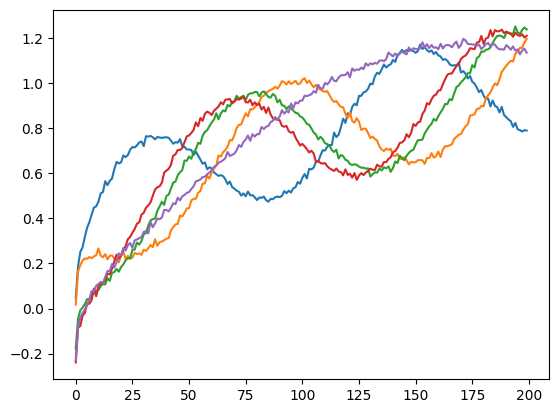

In [9]:
plt.plot(Y_train.squeeze(-2)[50:55].mT)

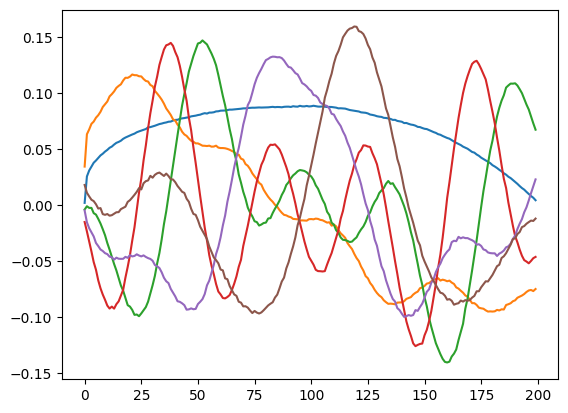

In [10]:
Y_train_pca.shape
Y_pca._pca.components_
plt.plot(Y_pca._pca.components_.mT)

## Visualize test data

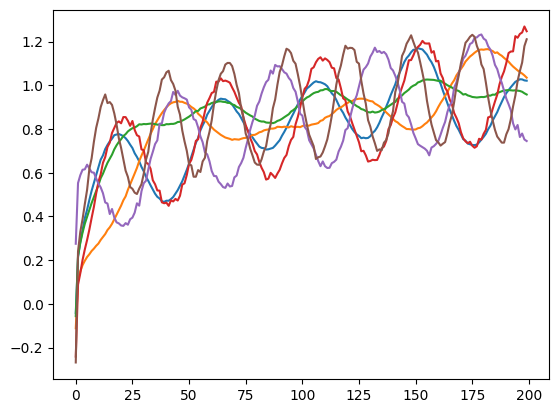

In [11]:
testidx = [in_sample[0], in_hull[0], out_hull[0]]

Y_test_decoded = Y_pca.decode(Y_test_pca)
plt.plot(Y_test_decoded[testidx].squeeze(-2).mT)
plt.plot(Y_test[testidx].squeeze(-2).mT)

In [12]:
# Variance explained in test data
1.0 - (Y_test - Y_test_decoded).var() / Y_test.var()

tensor(0.9472)

## Build and train unimodal model

In [13]:
#adam = pyro.optim.Adam({"lr": 0.001})
adam_seq = [pyro.optim.Adam({"lr": x}) for x in [0.001]]
elbo = pyro.infer.Trace_ELBO(num_particles = 1)

In [14]:
model = RegBNN.from_data(X_train, Y_train_pca, hidden_widths = hidden_widths)
guide = RegBNNGuide(model)

#svi = pyro.infer.SVI(model, guide, adam, elbo)
hmc = pyro.infer.NUTS(model.no_missing())

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


Step 1000, Elbo loss: 73176.6 +/- 43962.7 (slope = -75416.558 +/- 647.841 loss/k-iter, p-value = 0.000) + 
Step 2000, Elbo loss: 26074.5 +/- 14942.1 (slope = -25617.073 +/- 227.309 loss/k-iter, p-value = 0.000) + 
Step 3000, Elbo loss: 9962.7 +/- 5255.4 (slope = -9018.100 +/- 76.240 loss/k-iter, p-value = 0.000) + 
Step 4000, Elbo loss: 4169.9 +/- 1947.5 (slope = -3332.381 +/- 32.438 loss/k-iter, p-value = 0.000) + 
Step 5000, Elbo loss: 2010.3 +/- 751.7 (slope = -1268.392 +/- 18.417 loss/k-iter, p-value = 0.000) + 
Step 6000, Elbo loss: 1159.7 +/- 340.2 (slope = -538.646 +/- 15.083 loss/k-iter, p-value = 0.000) + 
Step 7000, Elbo loss: 788.0 +/- 191.1 (slope = -237.994 +/- 14.551 loss/k-iter, p-value = 0.000) + 
Step 8000, Elbo loss: 697.7 +/- 264.4 (slope = 190.802 +/- 26.336 loss/k-iter, p-value = 1.000) + *
Step 9000, Elbo loss: 1149.8 +/- 366.9 (slope = 211.227 +/- 37.925 loss/k-iter, p-value = 1.000) **
Step 10000, Elbo loss: 1210.5 +/- 473.0 (slope = 14.403 +/- 51.835 loss/k-ite

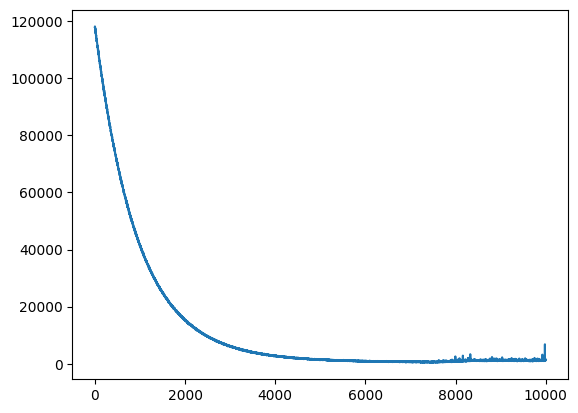

In [15]:
if method == "mcmc":
    mcmc = pyro.infer.MCMC(hmc, num_samples = 100, warmup_steps = 100)
    mcmc.run(X_pred = X_test)
    pred = Predictive(model, mcmc.get_samples())
    Y_pred_pca = pred.get_samples(X_pred = X_test)['mu_pred']
elif method == "svi":
    params = None
    losses = []
    for adam in adam_seq:
        svi = pyro.infer.SVI(model, guide, adam, elbo)
        params, new_losses = do_svi(svi, params = params)
        losses += new_losses
    plt.plot(losses)
    guide.eval()
    with param_store.scope(params):
        pred = Predictive(model, guide = guide, num_samples = 100)
        Y_pred_pca = pred.get_samples(X_pred = X_test)['mu_pred']
Y_pred = Y_pca.decode(Y_pred_pca)

In [16]:
def plot_predictions(Y_test, Y_pred, series_idx):
    Y_true = Y_test[series_idx].squeeze()
    Y_pred = Y_pred[:,series_idx].squeeze(-2).mT
    # Set up figure/axes
    fig, ax = plt.subplots(figsize=(10, 5))
    ylims = [1.5*Y_pred.min().detach() - 0.5*Y_pred.max().detach(), 1.5*Y_pred.max().detach() - 0.5*Y_pred.min().detach()]
    plt.ylim(ylims)
    # Plot true function
    ax.plot(Y_true, 'k-', linewidth=3, label="true function", zorder = 20)
    # Plot data points
    ax.plot(Y_pred, 'b-', linewidth=1, alpha=0.5, label="estimates", zorder = 15)

def plot_predictions_pca(Y_test_pca, Y_pred_pca, series_idx):
    Y_true_pca = Y_test_pca[series_idx]
    Y_pred_pca = Y_pred_pca[:,series_idx]
    colnames = [f"PC{n}" for n in range(Y_pred_pca.shape[-1])]
    data = pd.DataFrame(Y_pred_pca, columns=colnames)
    data["Type"] = "Pred"
    data_true = pd.DataFrame(Y_true_pca.unsqueeze(0), columns=colnames)
    data_true["Type"] = "True"
    g = sns.pairplot(pd.concat([data, data_true]), hue="Type", height = 1.5, diag_kind="hist")

In [17]:
random.shuffle(in_sample)
random.shuffle(in_hull)
random.shuffle(out_hull)

idx = 0

### In-sample

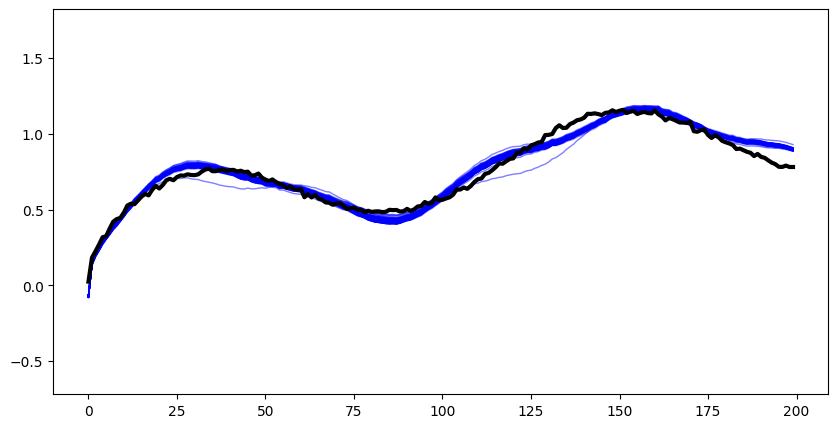

In [18]:
plot_predictions(Y_test, Y_pred, in_sample[idx])

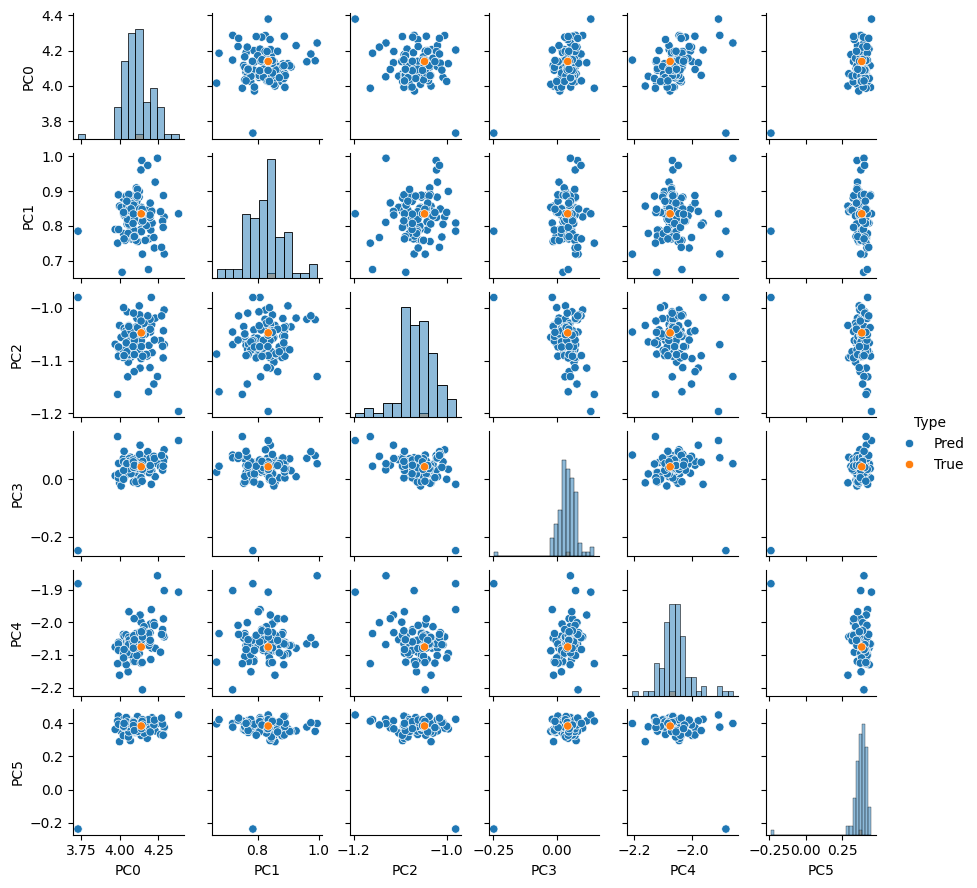

In [19]:
plot_predictions_pca(Y_test_pca, Y_pred_pca, in_sample[idx])

### Out of sample but within the convex hull

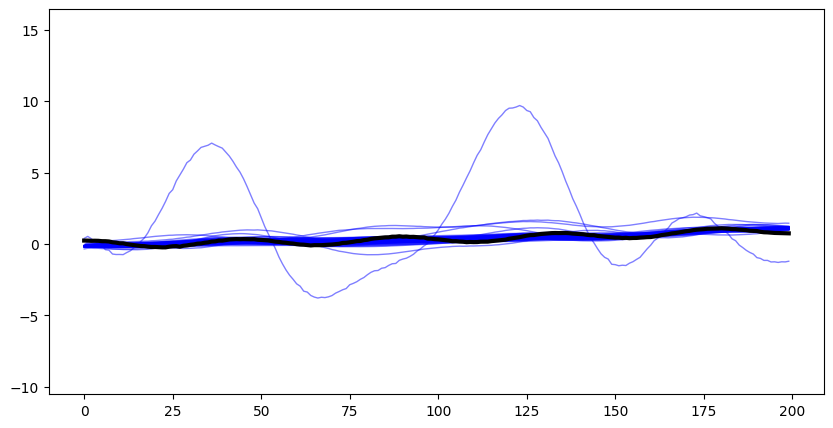

In [20]:
plot_predictions(Y_test, Y_pred, in_hull[idx])

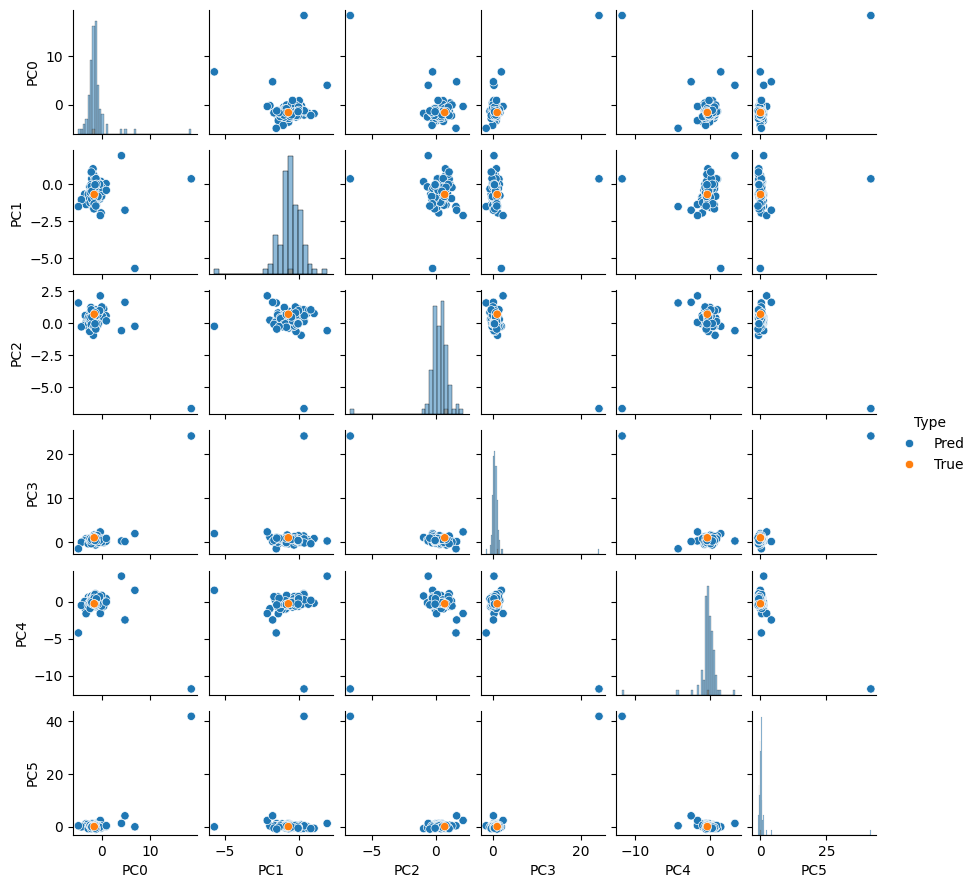

In [21]:
plot_predictions_pca(Y_test_pca, Y_pred_pca, in_hull[idx])

### Out of the convex hull

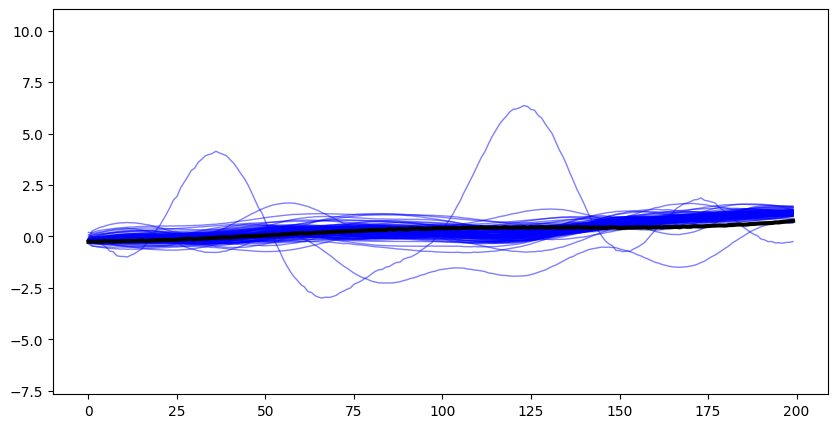

In [22]:
plot_predictions(Y_test, Y_pred, out_hull[idx])

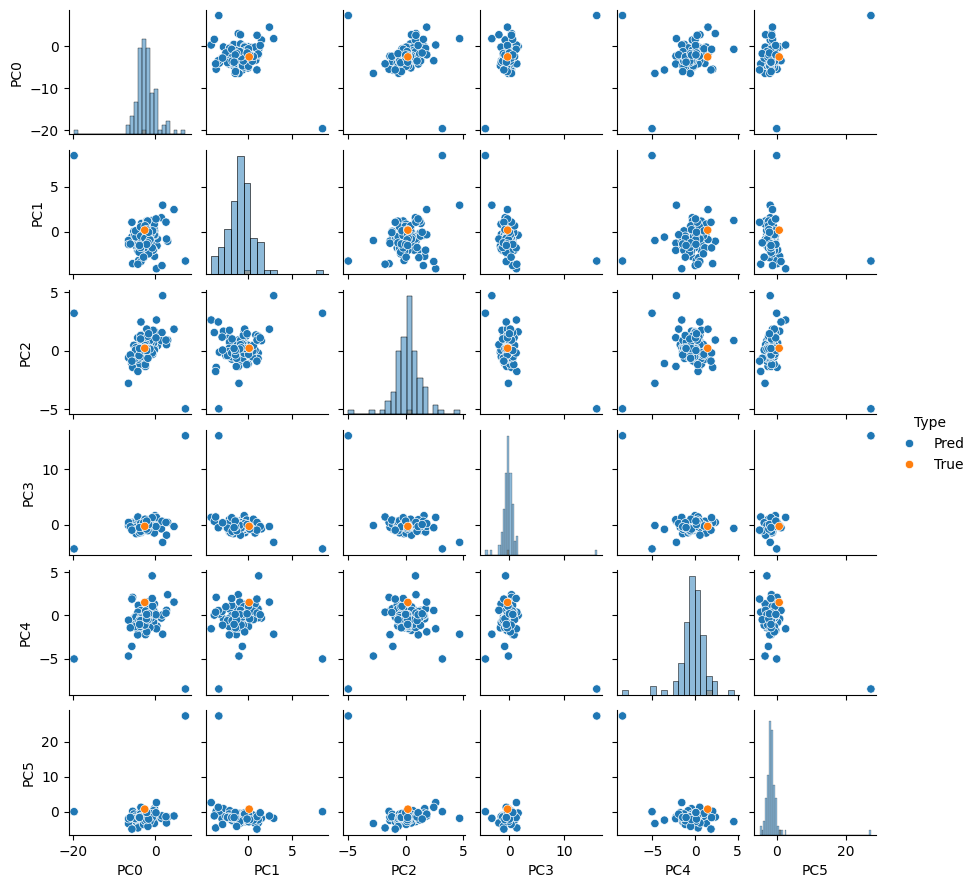

In [23]:
plot_predictions_pca(Y_test_pca, Y_pred_pca, out_hull[idx])

## Build and train a multimodal model

Set up multimodal training data:
* With the original X_train
* With an expanded X_train that significantly grows the convex hull of 

In [24]:
X_vals_full = [-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]
amp_log = math.log(0.25)
n_train_full = len(X_vals_full) ** 3
X_train_full = torch.zeros((n_train_full, 4))
noise = 0.05
modes = ["total_dist", "max_loc", "avg_slope"]

for i, xi in enumerate(itertools.product(X_vals_full, X_vals_full, X_vals_full)):
    X_train_full[i,0] = xi[0]
    X_train_full[i,1] = xi[1]
    X_train_full[i,2] = amp_log
    X_train_full[i,3] = xi[2]

# Original training data X values
Y_train_mm = torch.cat([timeseries_stat(X_train, m).unsqueeze(-1) for m in modes], dim=-1)
# Expanded training data X values
Y_train_mm_full = torch.cat([timeseries_stat(X_train_full, m).unsqueeze(-1) for m in modes], dim=-1)
# Test data
Y_test_mm = torch.cat([timeseries_stat(X_test, m).unsqueeze(-1) for m in modes], dim=-1)

In [25]:
model_mm = LayeredRegBNN.from_data(X_train, Y_train_pca, [X_train_full], [Y_train_mm_full], hidden_widths = hidden_widths)
guide_mm = LayeredRegBNNGuide(model_mm)

#svi_mm = pyro.infer.SVI(model_mm, guide_mm, adam, elbo)
hmc_mm = pyro.infer.NUTS(model_mm.no_missing())

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


Step 1000, Elbo loss: 76292.1 +/- 43122.5 (slope = -74004.542 +/- 621.571 loss/k-iter, p-value = 0.000) + 
Step 2000, Elbo loss: 29365.6 +/- 15338.6 (slope = -26322.013 +/- 221.704 loss/k-iter, p-value = 0.000) + 
Step 3000, Elbo loss: 12502.9 +/- 5672.7 (slope = -9736.990 +/- 80.887 loss/k-iter, p-value = 0.000) + 
Step 4000, Elbo loss: 6132.5 +/- 2223.6 (slope = -3805.204 +/- 36.878 loss/k-iter, p-value = 0.000) + 
Step 5000, Elbo loss: 3575.1 +/- 955.7 (slope = -1610.430 +/- 24.002 loss/k-iter, p-value = 0.000) + 
Step 6000, Elbo loss: 2434.6 +/- 471.8 (slope = -739.696 +/- 21.922 loss/k-iter, p-value = 0.000) + 
Step 7000, Elbo loss: 1907.0 +/- 283.8 (slope = -367.282 +/- 20.662 loss/k-iter, p-value = 0.000) + 
Step 8000, Elbo loss: 1629.2 +/- 225.3 (slope = -210.515 +/- 20.786 loss/k-iter, p-value = 0.000) + 
Step 9000, Elbo loss: 1447.4 +/- 206.1 (slope = -135.995 +/- 20.879 loss/k-iter, p-value = 0.000) + 
Step 10000, Elbo loss: 1309.3 +/- 213.2 (slope = -140.877 +/- 21.601 loss

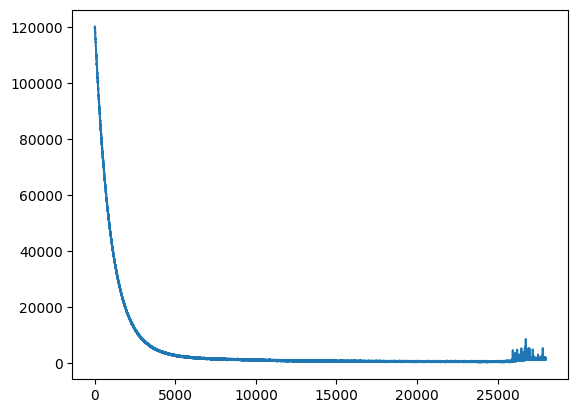

In [26]:
if method == "mcmc":
    mcmc_mm = pyro.infer.MCMC(hmc_mm, num_samples = 100, warmup_steps = 100)
    mcmc_mm.run(X_pred = X_test)
    pred_mm = Predictive(model_mm, mcmc_mm.get_samples())
    Y_pred_mm_pca = pred_mm.get_samples(X_pred = X_test)['mu_pred']
elif method == "svi":
    params_mm = None
    losses_mm = []
    for adam in adam_seq:
        svi_mm = pyro.infer.SVI(model_mm, guide_mm, adam, elbo)
        params_mm, new_losses = do_svi(svi_mm, params = params_mm)
        losses_mm += new_losses
    plt.plot(losses_mm)
    guide_mm.eval()
    with param_store.scope(params_mm):
        pred_mm = Predictive(model_mm, guide = guide_mm, num_samples = 100)
        Y_pred_mm_pca = pred_mm.get_samples(X_pred = X_test)['mu_pred']
Y_pred_mm = Y_pca.decode(Y_pred_mm_pca)

### In-sample

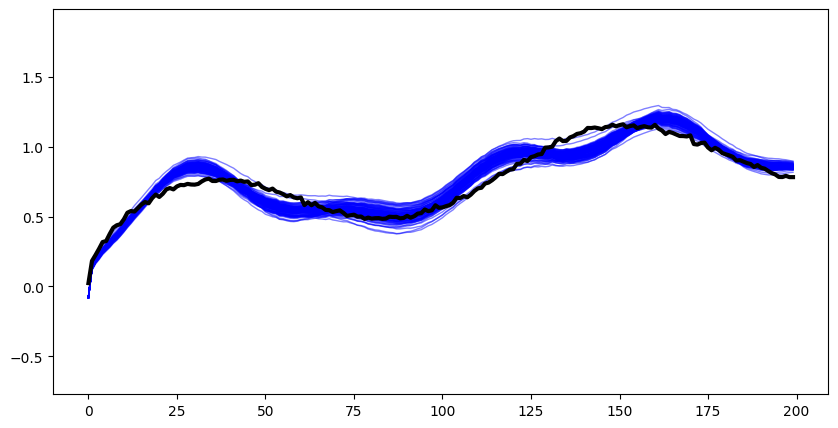

In [27]:
plot_predictions(Y_test, Y_pred_mm, in_sample[idx])

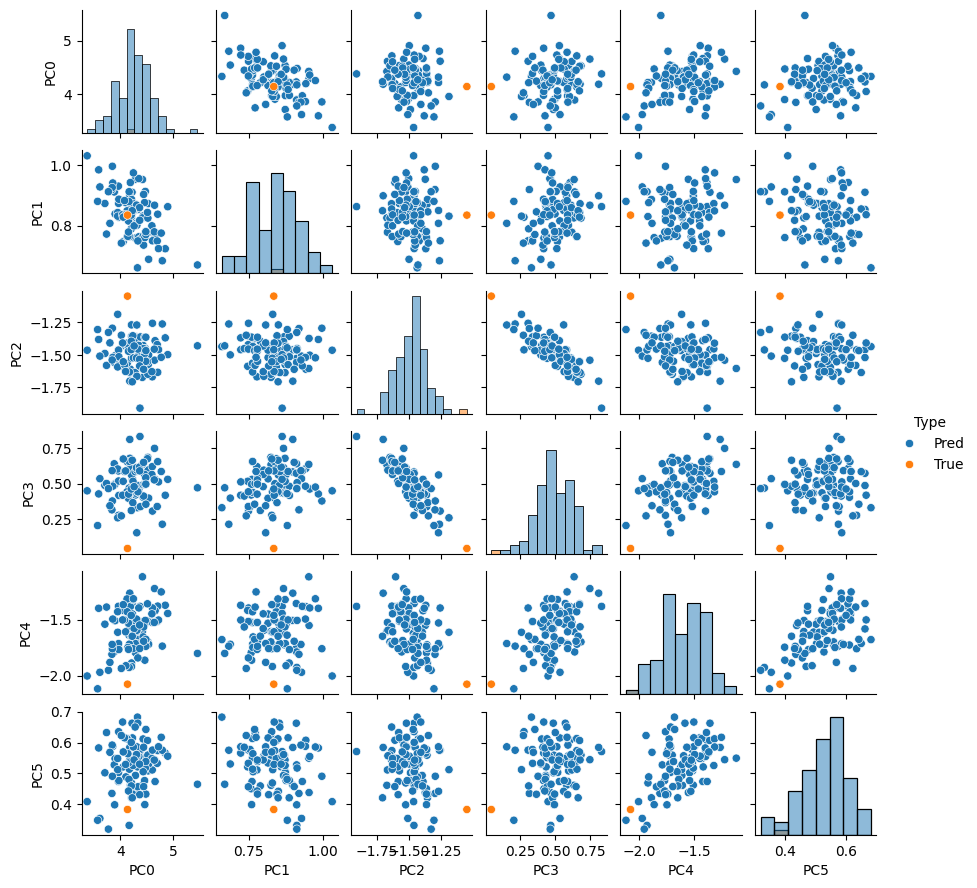

In [28]:
plot_predictions_pca(Y_test_pca, Y_pred_mm_pca, in_sample[idx])

### Out of sample but within the convex hull

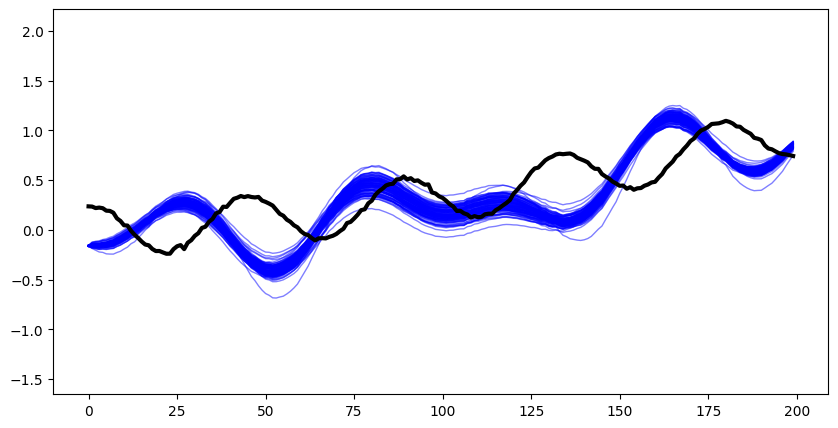

In [29]:
plot_predictions(Y_test, Y_pred_mm, in_hull[idx])

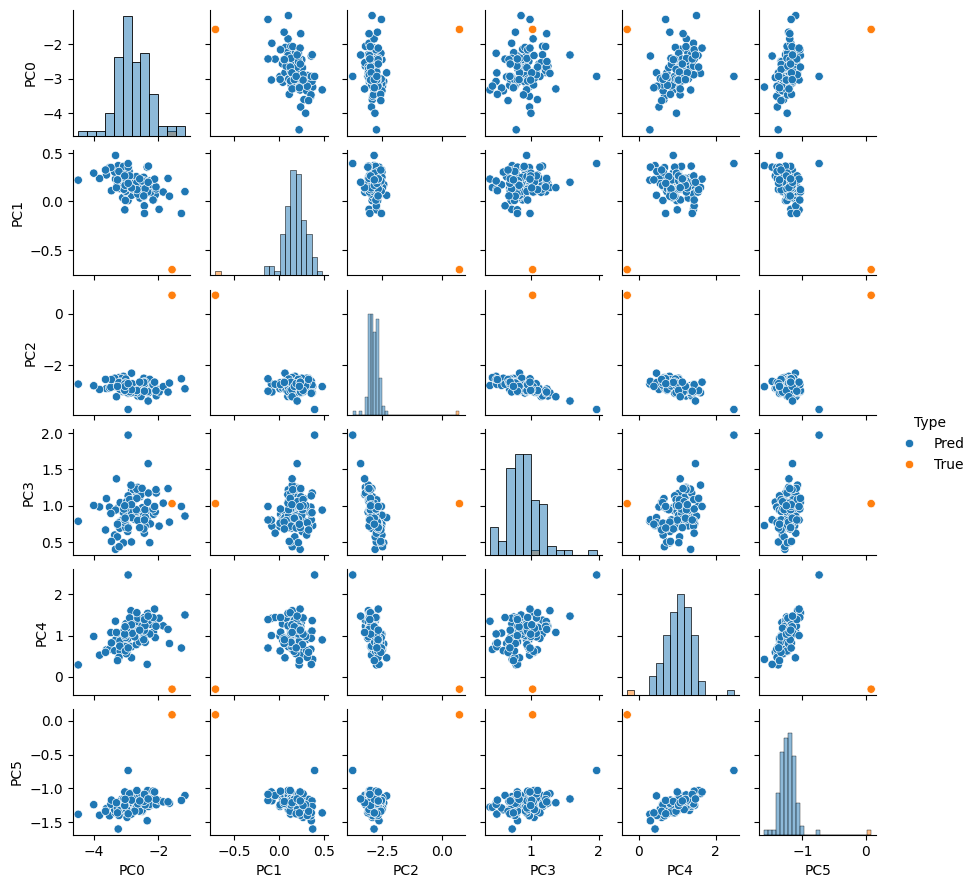

In [30]:
plot_predictions_pca(Y_test_pca, Y_pred_mm_pca, in_hull[idx])

### Out of the convex hull

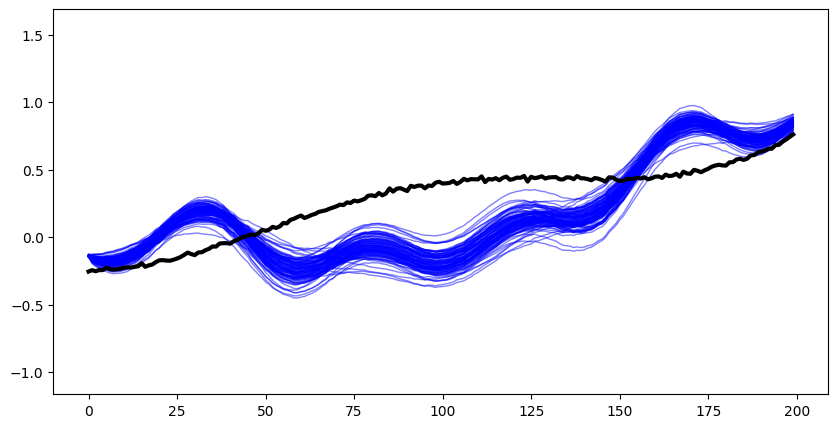

In [31]:
plot_predictions(Y_test, Y_pred_mm, out_hull[idx])

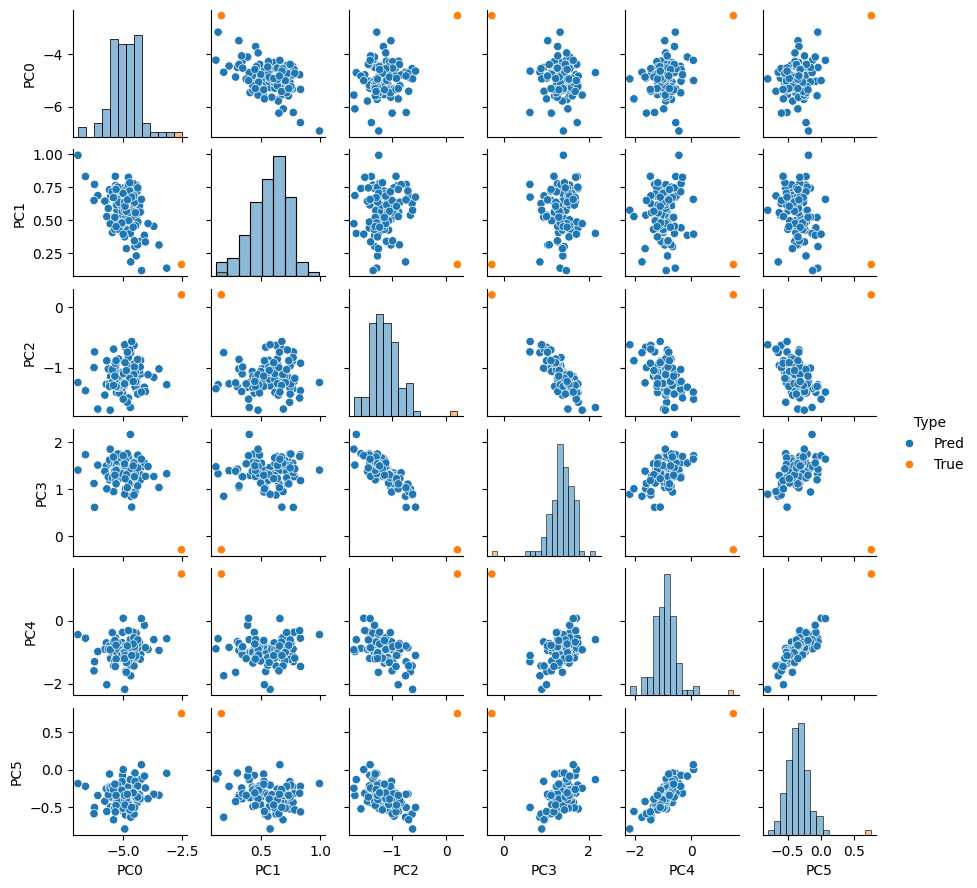

In [32]:
plot_predictions_pca(Y_test_pca, Y_pred_mm_pca, out_hull[idx])

## Compare unimodal and multimodal models on the whole

Compare bias and uncertainty for in-sample, in-hull and out of hull test points

### Bias

Difference between true point and mean of posterior predictions

Text(0, 0.5, 'Multimodal')

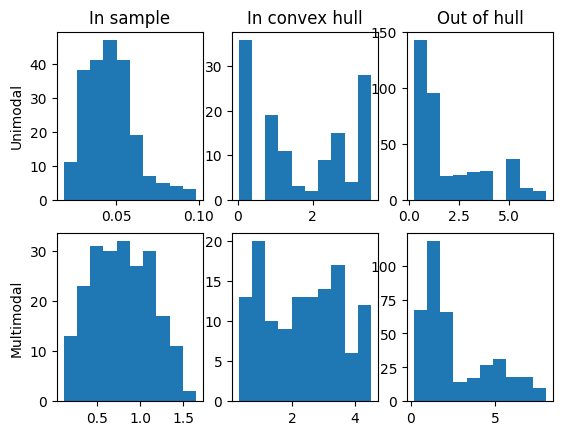

In [33]:
Y_bias_pca = (Y_pred_pca.mean(dim=0) - Y_test_pca).pow(2).sum(dim=-1).sqrt() # Combine bias in Euclidian distance fashion
Y_bias_mm_pca = (Y_pred_mm_pca.mean(dim=0) - Y_test_pca).pow(2).sum(dim=-1).sqrt()

fig, axs = plt.subplots(2,3)
# Unimodal, in sample
axs[0,0].hist(Y_bias_pca[in_sample])
# Unimodal, in hull
axs[0,1].hist(Y_bias_pca[in_hull])
# Unimodal, out hull
axs[0,2].hist(Y_bias_pca[out_hull])
# Multimodal, in sample
axs[1,0].hist(Y_bias_mm_pca[in_sample])
# Multimodal, in hull
axs[1,1].hist(Y_bias_mm_pca[in_hull])
# Multimodal, out hull
axs[1,2].hist(Y_bias_mm_pca[out_hull])

# Titles
axs[0,0].set_title("In sample")
axs[0,1].set_title("In convex hull")
axs[0,2].set_title("Out of hull")
axs[0,0].set_ylabel("Unimodal")
axs[1,0].set_ylabel("Multimodal")

Text(0, 0.5, 'Multimodal')

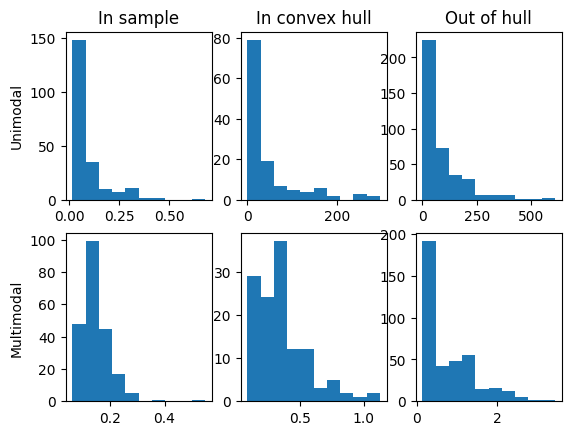

In [34]:
Y_var_pca = Y_pred_pca.var(dim=0).sum(dim=-1) # Add marginal variances
Y_var_mm_pca = Y_pred_mm_pca.var(dim=0).sum(dim=-1)

fig, axs = plt.subplots(2,3)
# Unimodal, in sample
axs[0,0].hist(Y_var_pca[in_sample])
# Unimodal, in hull
axs[0,1].hist(Y_var_pca[in_hull])
# Unimodal, out hull
axs[0,2].hist(Y_var_pca[out_hull])
# Multimodal, in sample
axs[1,0].hist(Y_var_mm_pca[in_sample])
# Multimodal, in hull
axs[1,1].hist(Y_var_mm_pca[in_hull])
# Multimodal, out hull
axs[1,2].hist(Y_var_mm_pca[out_hull])

# Titles
axs[0,0].set_title("In sample")
axs[0,1].set_title("In convex hull")
axs[0,2].set_title("Out of hull")
axs[0,0].set_ylabel("Unimodal")
axs[1,0].set_ylabel("Multimodal")

## "Fake" multimodal model

Skip the auxiliary surrogate model and just pass the true aux variables in as training features.

In [35]:
X_train_fakemm = torch.cat([X_train, Y_train_mm], dim=-1)
X_test_fakemm = torch.cat([X_test, Y_test_mm], dim=-1)

In [36]:
model_fakemm = RegBNN.from_data(X_train_fakemm, Y_train_pca, hidden_widths = hidden_widths)
guide_fakemm = RegBNNGuide(model_fakemm)

#svi_fakemm = pyro.infer.SVI(model_fakemm, guide_fakemm, adam, elbo)
hmc_fakemm = pyro.infer.NUTS(model_fakemm.no_missing())

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


Step 1000, Elbo loss: 73956.5 +/- 44526.3 (slope = -76395.503 +/- 650.432 loss/k-iter, p-value = 0.000) + 
Step 2000, Elbo loss: 26028.3 +/- 15312.7 (slope = -26251.461 +/- 233.405 loss/k-iter, p-value = 0.000) + 
Step 3000, Elbo loss: 9589.5 +/- 5309.9 (slope = -9105.473 +/- 79.865 loss/k-iter, p-value = 0.000) + 
Step 4000, Elbo loss: 3805.1 +/- 1901.1 (slope = -3255.074 +/- 30.747 loss/k-iter, p-value = 0.000) + 
Step 5000, Elbo loss: 1721.0 +/- 702.7 (slope = -1189.780 +/- 16.038 loss/k-iter, p-value = 0.000) + 
Step 6000, Elbo loss: 949.6 +/- 278.3 (slope = -448.776 +/- 11.090 loss/k-iter, p-value = 0.000) + 
Step 7000, Elbo loss: 648.7 +/- 138.2 (slope = -174.507 +/- 10.355 loss/k-iter, p-value = 0.000) + 
Step 8000, Elbo loss: 526.8 +/- 102.7 (slope = -76.899 +/- 10.144 loss/k-iter, p-value = 0.000) + 
Step 9000, Elbo loss: 463.5 +/- 91.8 (slope = -46.068 +/- 9.627 loss/k-iter, p-value = 0.000) + 
Step 10000, Elbo loss: 428.3 +/- 94.4 (slope = -25.204 +/- 10.225 loss/k-iter, p-v

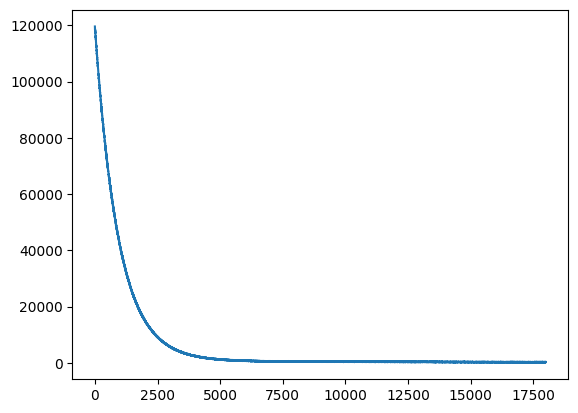

In [37]:
if method == "mcmc":
    mcmc_fakemm = pyro.infer.MCMC(hmc_fakemm, num_samples = 100, warmup_steps = 100)
    mcmc_fakemm.run(X_pred = X_test_fakemm)
    pred_fakemm = Predictive(model_fakemm, mcmc_fakemm.get_samples())
    Y_pred_fakemm_pca = pred.get_samples(X_pred = X_test_fakemm)['mu_pred']
elif method == "svi":
    params_fakemm = None
    losses_fakemm = []
    for adam in adam_seq:
        svi_fakemm = pyro.infer.SVI(model_fakemm, guide_fakemm, adam, elbo)
        params_fakemm, new_losses = do_svi(svi_fakemm, params = params_fakemm)
        losses_fakemm += new_losses
    plt.plot(losses_fakemm)
    guide_fakemm.eval()
    with param_store.scope(params_fakemm):
        pred_fakemm = Predictive(model_fakemm, guide = guide_fakemm, num_samples = 100)
        Y_pred_fakemm_pca = pred_fakemm.get_samples(X_pred = X_test_fakemm)['mu_pred']
Y_pred_fakemm = Y_pca.decode(Y_pred_fakemm_pca)

### In sample

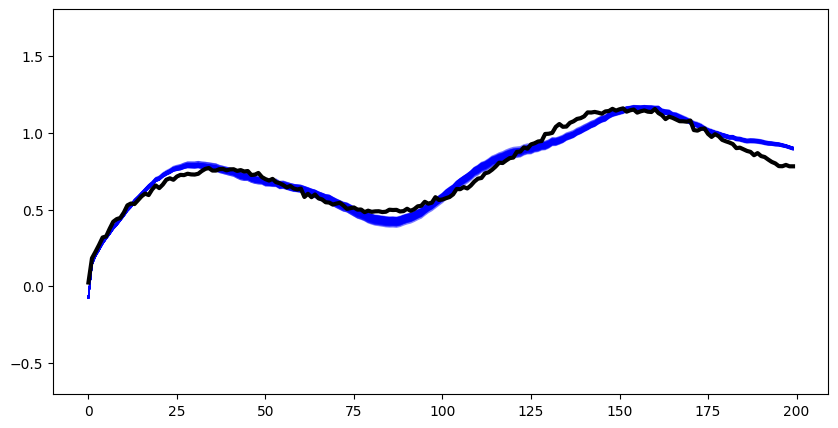

In [38]:
plot_predictions(Y_test, Y_pred_fakemm, in_sample[idx])

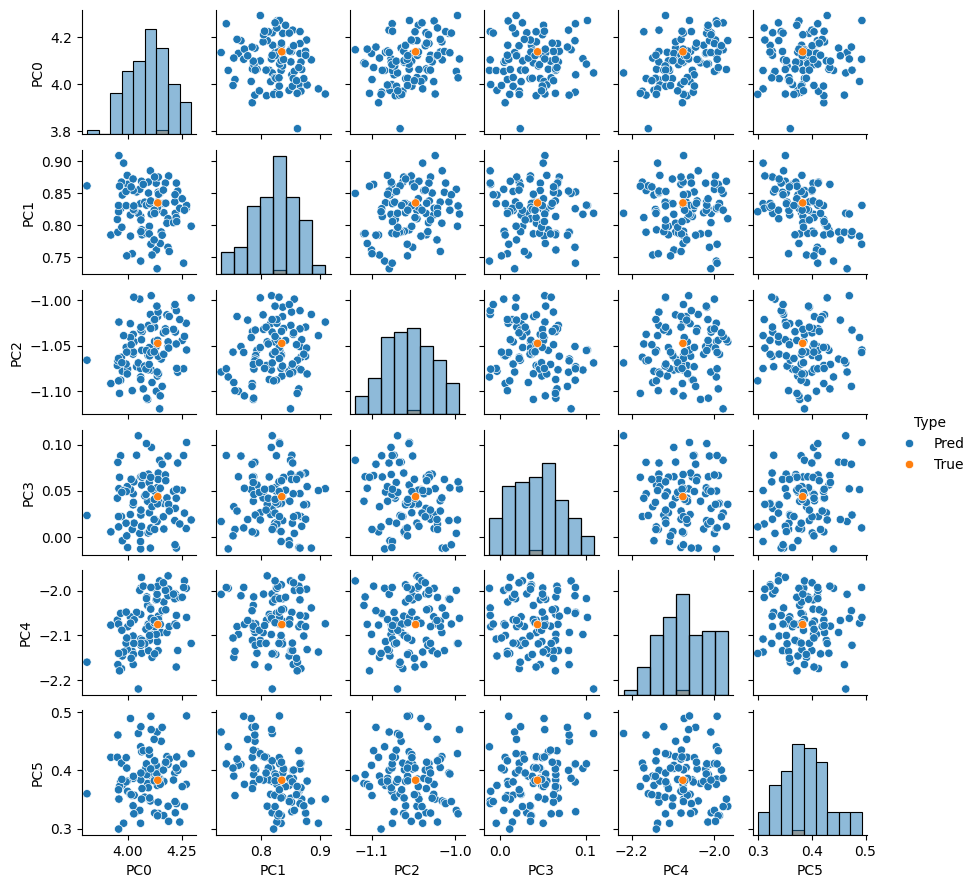

In [39]:
plot_predictions_pca(Y_test_pca, Y_pred_fakemm_pca, in_sample[idx])

### Out of sample but in convex hull

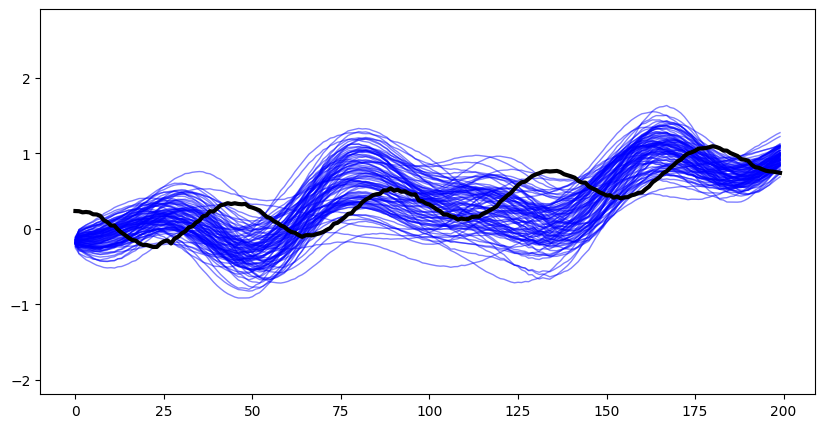

In [40]:
plot_predictions(Y_test, Y_pred_fakemm, in_hull[idx])

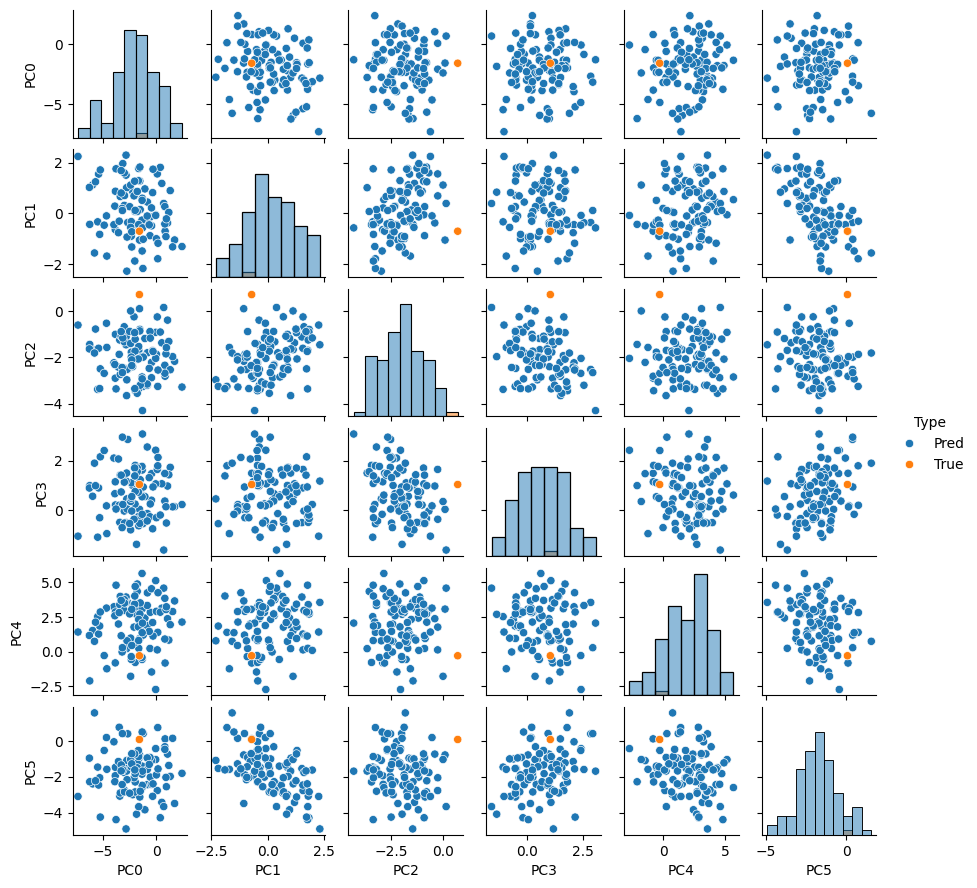

In [41]:
plot_predictions_pca(Y_test_pca, Y_pred_fakemm_pca, in_hull[idx])

### Out of convex hull

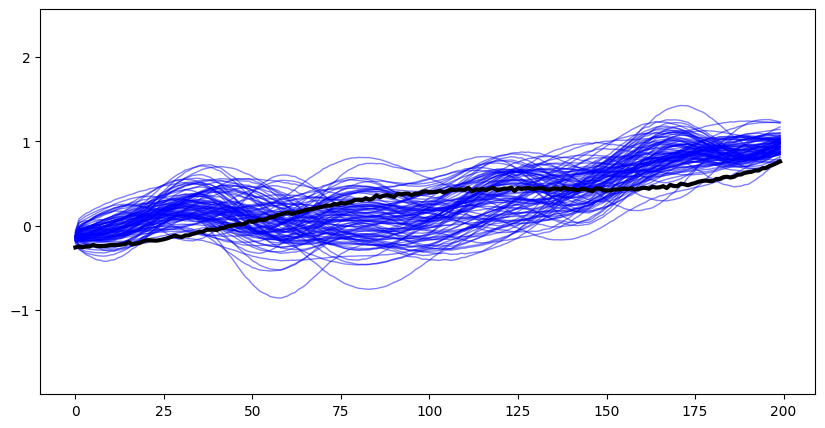

In [42]:
plot_predictions(Y_test, Y_pred_fakemm, out_hull[idx])

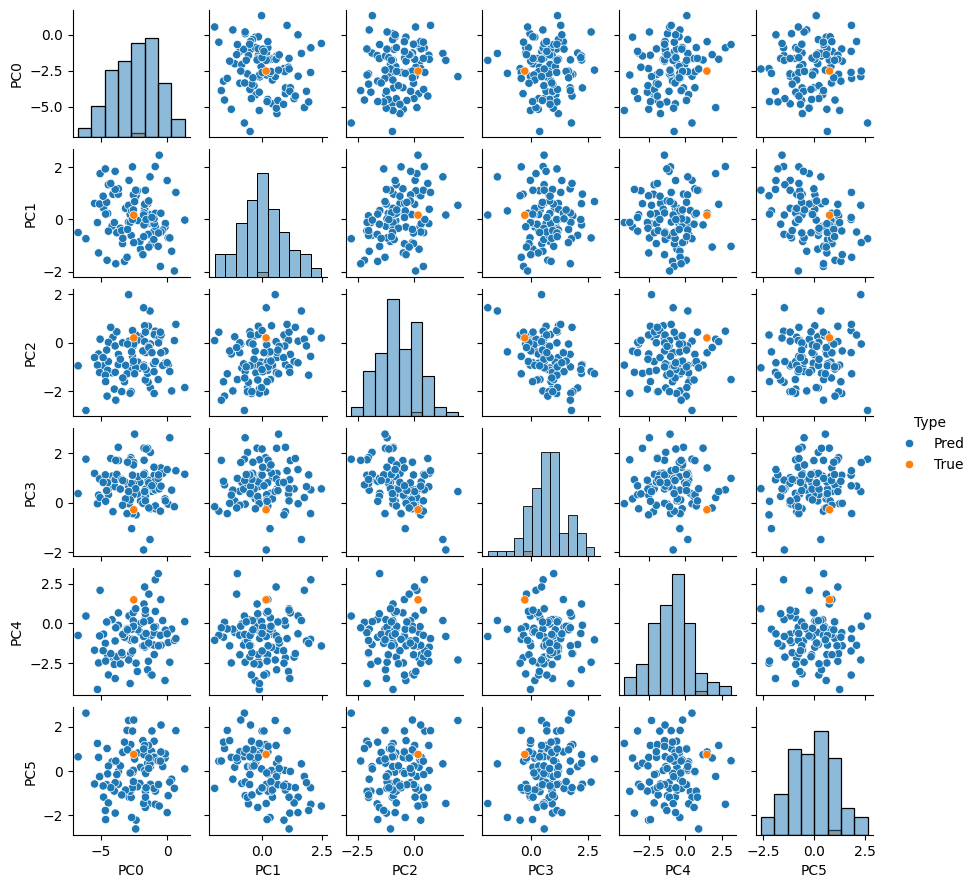

In [43]:
plot_predictions_pca(Y_test_pca, Y_pred_fakemm_pca, out_hull[idx])

### Evaluate Fake multimodal model vs unimodal model overall

#### Bias

Text(0, 0.5, "'Fake' Multimodal")

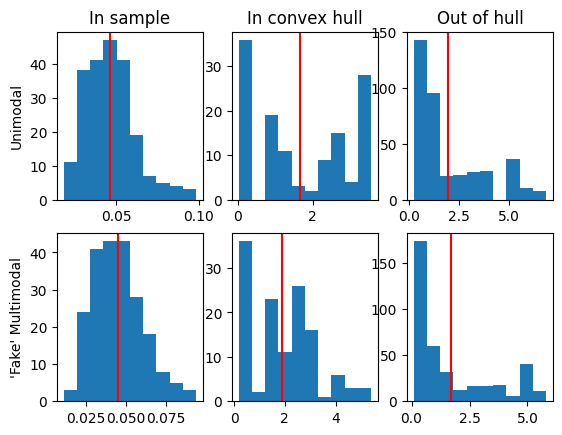

In [44]:
Y_bias_fakemm_pca = (Y_pred_fakemm_pca.mean(dim=0) - Y_test_pca).pow(2).sum(dim = -1).sqrt()

fig, axs = plt.subplots(2,3)
# Unimodal, in sample
axs[0,0].hist(Y_bias_pca[in_sample])
axs[0,0].axvline(Y_bias_pca[in_sample].mean(), color="red")
# Unimodal, in hull
axs[0,1].hist(Y_bias_pca[in_hull])
axs[0,1].axvline(Y_bias_pca[in_hull].mean(), color="red")
# Unimodal, out hull
axs[0,2].hist(Y_bias_pca[out_hull])
axs[0,2].axvline(Y_bias_pca[out_hull].mean(), color="red")
# Multimodal, in sample
axs[1,0].hist(Y_bias_fakemm_pca[in_sample])
axs[1,0].axvline(Y_bias_fakemm_pca[in_sample].mean(), color="red")
# Multimodal, in hull
axs[1,1].hist(Y_bias_fakemm_pca[in_hull])
axs[1,1].axvline(Y_bias_fakemm_pca[in_hull].mean(), color="red")
# Multimodal, out hull
axs[1,2].hist(Y_bias_fakemm_pca[out_hull])
axs[1,2].axvline(Y_bias_fakemm_pca[out_hull].mean(), color="red")

# Titles
axs[0,0].set_title("In sample")
axs[0,1].set_title("In convex hull")
axs[0,2].set_title("Out of hull")
axs[0,0].set_ylabel("Unimodal")
axs[1,0].set_ylabel("'Fake' Multimodal")

#### Variance

Text(0, 0.5, "'Fake' Multimodal")

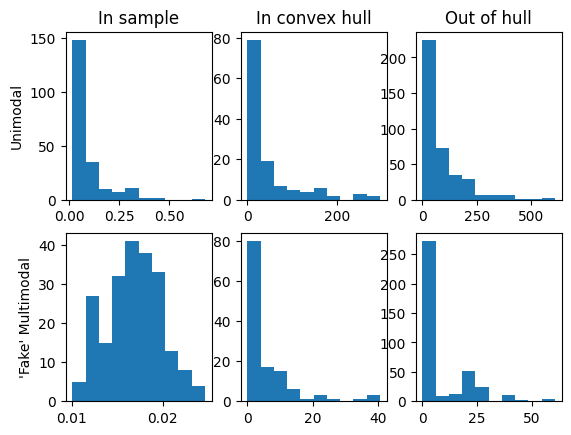

In [45]:

Y_var_fakemm_pca = Y_pred_fakemm_pca.var(dim=0).sum(dim=-1)

fig, axs = plt.subplots(2,3)
# Unimodal, in sample
axs[0,0].hist(Y_var_pca[in_sample])
# Unimodal, in hull
axs[0,1].hist(Y_var_pca[in_hull])
# Unimodal, out hull
axs[0,2].hist(Y_var_pca[out_hull])
# Multimodal, in sample
axs[1,0].hist(Y_var_fakemm_pca[in_sample])
# Multimodal, in hull
axs[1,1].hist(Y_var_fakemm_pca[in_hull])
# Multimodal, out hull
axs[1,2].hist(Y_var_fakemm_pca[out_hull])

# Titles
axs[0,0].set_title("In sample")
axs[0,1].set_title("In convex hull")
axs[0,2].set_title("Out of hull")
axs[0,0].set_ylabel("Unimodal")
axs[1,0].set_ylabel("'Fake' Multimodal")

#### Normalized Error

Text(0, 0.5, "'Fake' Multimodal")

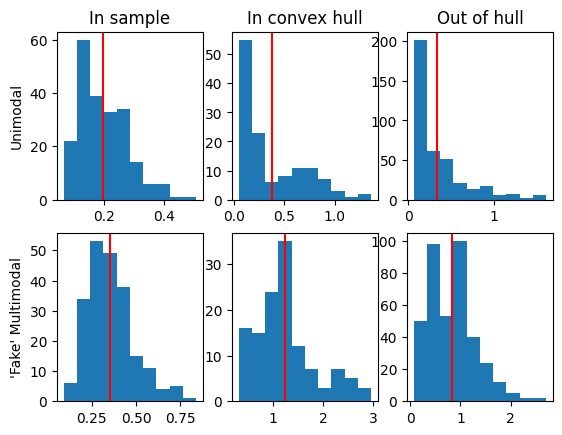

In [46]:
Y_zscore_pca = Y_bias_pca / Y_var_pca.sqrt()
Y_zscore_fakemm_pca = Y_bias_fakemm_pca / Y_var_fakemm_pca.sqrt()

fig, axs = plt.subplots(2,3)
# Unimodal, in sample
axs[0,0].hist(Y_zscore_pca[in_sample])
axs[0,0].axvline(Y_zscore_pca[in_sample].mean(), color="red")
# Unimodal, in hull
axs[0,1].hist(Y_zscore_pca[in_hull])
axs[0,1].axvline(Y_zscore_pca[in_hull].mean(), color="red")
# Unimodal, out hull
axs[0,2].hist(Y_zscore_pca[out_hull])
axs[0,2].axvline(Y_zscore_pca[out_hull].mean(), color="red")
# Multimodal, in sample
axs[1,0].hist(Y_zscore_fakemm_pca[in_sample])
axs[1,0].axvline(Y_zscore_fakemm_pca[in_sample].mean(), color="red")
# Multimodal, in hull
axs[1,1].hist(Y_zscore_fakemm_pca[in_hull])
axs[1,1].axvline(Y_zscore_fakemm_pca[in_hull].mean(), color="red")
# Multimodal, out hull
axs[1,2].hist(Y_zscore_fakemm_pca[out_hull])
axs[1,2].axvline(Y_zscore_fakemm_pca[out_hull].mean(), color="red")

# Titles
axs[0,0].set_title("In sample")
axs[0,1].set_title("In convex hull")
axs[0,2].set_title("Out of hull")
axs[0,0].set_ylabel("Unimodal")
axs[1,0].set_ylabel("'Fake' Multimodal")